In [13]:
%pip install folium ipython

Note: you may need to restart the kernel to use updated packages.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from IPython.display import display

In [3]:
# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Set pandas option to display all columns
pd.set_option('display.max_columns', None)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree,Agree,Agree,Agree,Neither agree nor disa

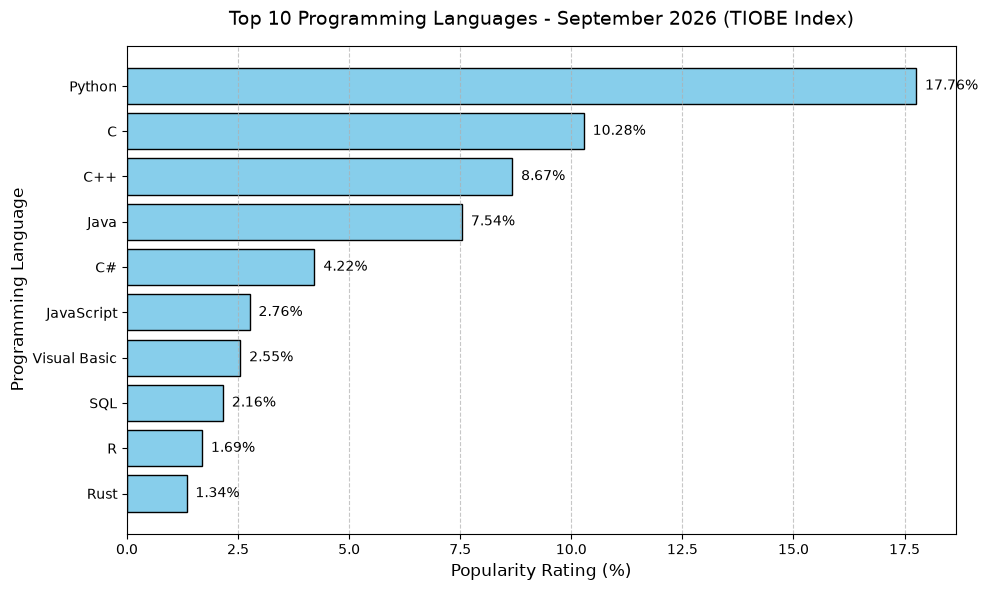

In [4]:
languages = ['Python', 'C', 'C++', 'Java', 'C#', 'JavaScript', 'Visual Basic', 'SQL', 'R', 'Rust']
ratings = [17.76, 10.28, 8.67, 7.54, 4.22, 2.76, 2.55, 2.16, 1.69, 1.34]

# Reverse order so the highest is at the top of a horizontal bar chart
languages = languages[::-1]
ratings = ratings[::-1]

plt.figure(figsize=(10, 6))
bars = plt.barh(languages, ratings, color='skyblue', edgecolor='black')

plt.title('Top 10 Programming Languages - September 2026 (TIOBE Index)', fontsize=14, pad=15)
plt.xlabel('Popularity Rating (%)', fontsize=12)
plt.ylabel('Programming Language', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add data labels
for bar in bars:
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width()}%', 
             va='center', ha='left', fontsize=10)

plt.tight_layout()

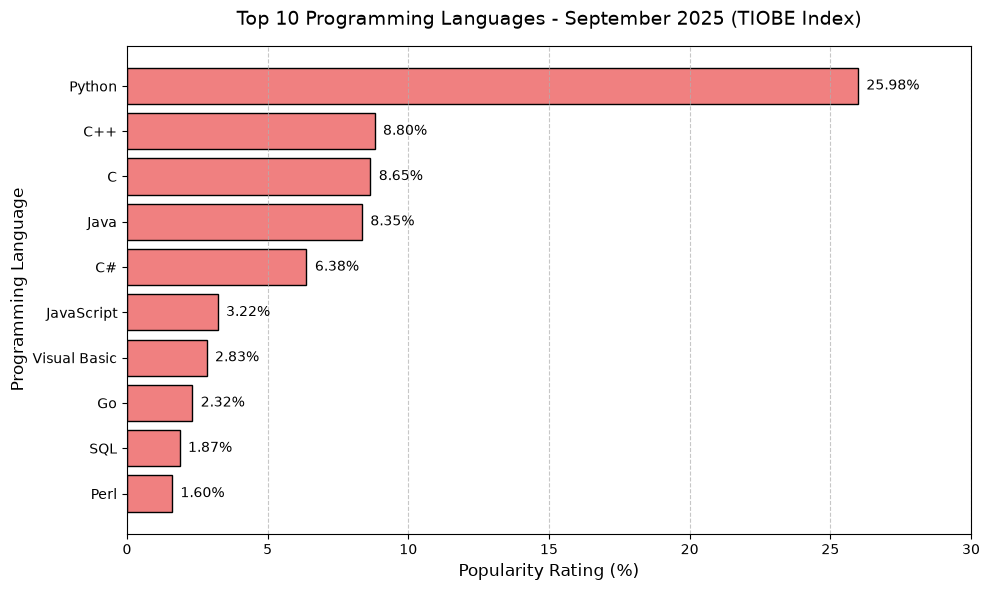

In [5]:
languages = ['Python', 'C++', 'C', 'Java', 'C#', 'JavaScript', 'Visual Basic', 'Go', 'SQL', 'Perl']
# Estimated values based on September 2025 rankings and YoY differences from 2026 data
ratings = [25.98, 8.80, 8.65, 8.35, 6.38, 3.22, 2.83, 2.32, 1.87, 1.60]

# Reverse order so the highest is at the top of a horizontal bar chart
languages = languages[::-1]
ratings = ratings[::-1]

plt.figure(figsize=(10, 6))
bars = plt.barh(languages, ratings, color='lightcoral', edgecolor='black')

plt.title('Top 10 Programming Languages - September 2025 (TIOBE Index)', fontsize=14, pad=15)
plt.xlabel('Popularity Rating (%)', fontsize=12)
plt.ylabel('Programming Language', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add data labels
for bar in bars:
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.2f}%', 
             va='center', ha='left', fontsize=10)

# Set x-axis limit slightly higher to accommodate the large Python label
plt.xlim(0, 30)
plt.tight_layout()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


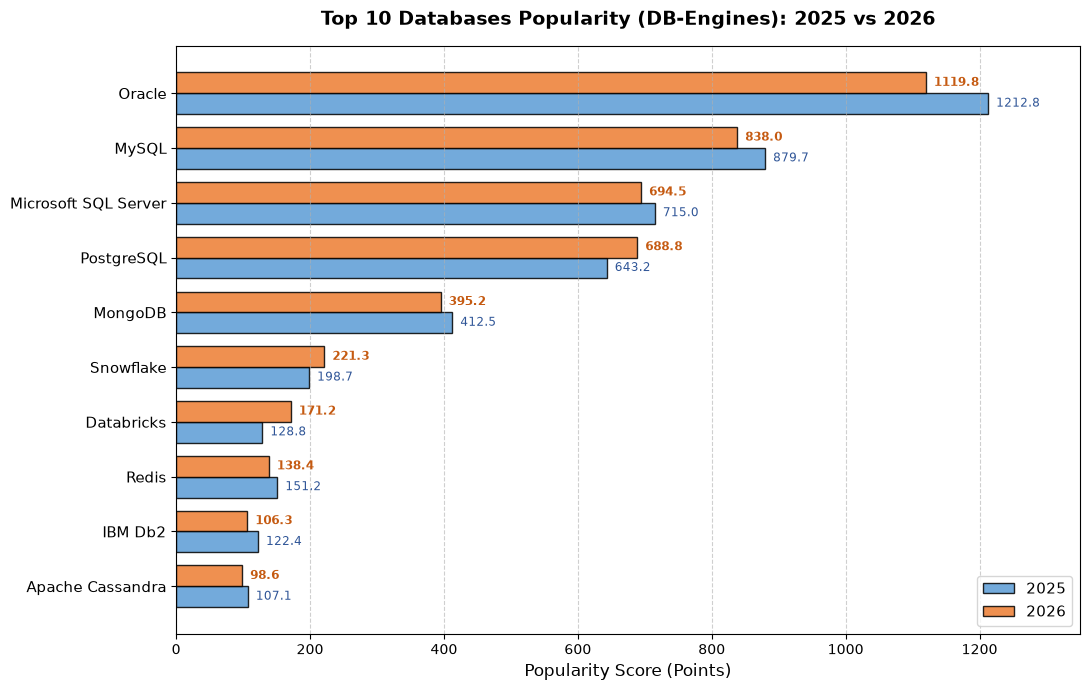

In [6]:
# Top 10 Database Management Systems (DB-Engines Ranking / Popularity Scores)
databases = [
    "Oracle",
    "MySQL",
    "Microsoft SQL Server",
    "PostgreSQL",
    "MongoDB",
    "Snowflake",
    "Databricks",
    "Redis",
    "IBM Db2",
    "Apache Cassandra",
]

# Popularity scores (YOY comparison: 2025 vs 2026)
scores_2025 = [1212.77, 879.66, 715.05, 643.19, 412.50, 198.65, 128.80, 151.20, 122.37, 107.12]
scores_2026 = [1119.79, 837.96, 694.47, 688.75, 395.20, 221.30, 171.24, 138.45, 106.29, 98.60]

# Reverse order so #1 appears at the top of the horizontal bar chart
databases = databases[::-1]
scores_2025 = scores_2025[::-1]
scores_2026 = scores_2026[::-1]

y = np.arange(len(databases))
height = 0.38

fig, ax = plt.subplots(figsize=(11, 7))

bars_2025 = ax.barh(y - height / 2, scores_2025, height, label="2025", color="#5B9BD5", edgecolor="black", alpha=0.85)
bars_2026 = ax.barh(y + height / 2, scores_2026, height, label="2026", color="#ED7D31", edgecolor="black", alpha=0.85)

ax.set_title("Top 10 Databases Popularity (DB-Engines): 2025 vs 2026", fontsize=14, pad=15, fontweight="bold")
ax.set_xlabel("Popularity Score (Points)", fontsize=12)
ax.set_yticks(y)
ax.set_yticklabels(databases, fontsize=11)
ax.legend(loc="lower right", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.6)
ax.set_xlim(0, 1350)

# Add numeric value labels
for bar in bars_2025:
    width = bar.get_width()
    ax.text(width + 12, bar.get_y() + bar.get_height() / 2, f"{width:.1f}", va="center", ha="left", fontsize=8.5, color="#2F5597")

for bar in bars_2026:
    width = bar.get_width()
    ax.text(width + 12, bar.get_y() + bar.get_height() / 2, f"{width:.1f}", va="center", ha="left", fontsize=8.5, color="#C55A11", fontweight="semibold")

plt.tight_layout()
plt.show()

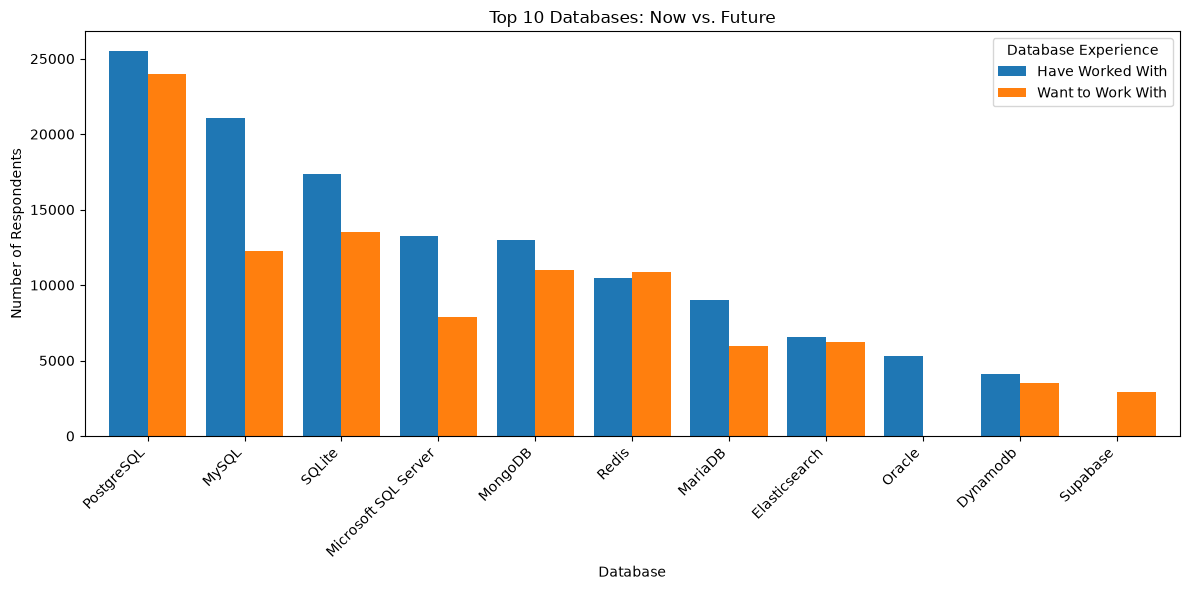

In [7]:
# Count each database, splitting multiple selections
have_counts = (
    df["DatabaseHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

want_counts = (
    df["DatabaseWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Combine the results
comparison = pd.concat(
    [
        have_counts.rename("Have Worked With"),
        want_counts.rename("Want to Work With")
    ],
    axis=1
).fillna(0)

# Plot a grouped bar chart
comparison.plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title("Top 10 Databases: Now vs. Future")
plt.xlabel("Database")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Database Experience")
plt.tight_layout()
plt.show()

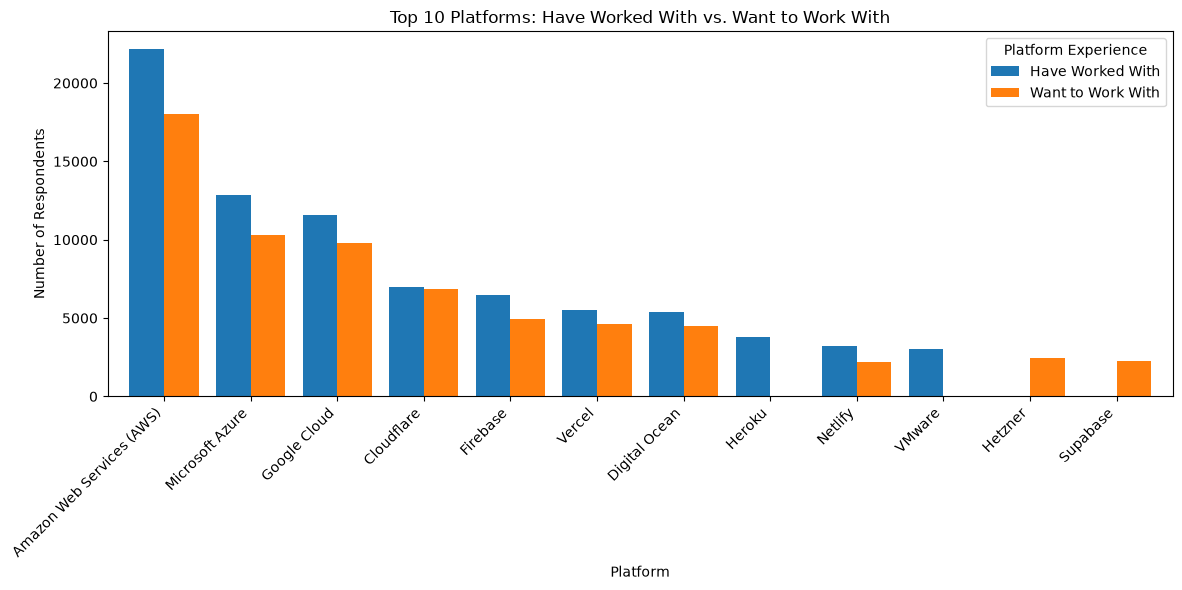

In [8]:
# Count the top 10 platforms respondents have worked with
have_counts = (
    df["PlatformHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Count the top 10 platforms respondents want to work with
want_counts = (
    df["PlatformWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Combine both datasets
comparison = pd.concat(
    [
        have_counts.rename("Have Worked With"),
        want_counts.rename("Want to Work With")
    ],
    axis=1
).fillna(0)

# Create grouped bar chart
ax = comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Top 10 Platforms: Have Worked With vs. Want to Work With")
plt.xlabel("Platform")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Platform Experience")
plt.tight_layout()
plt.show()

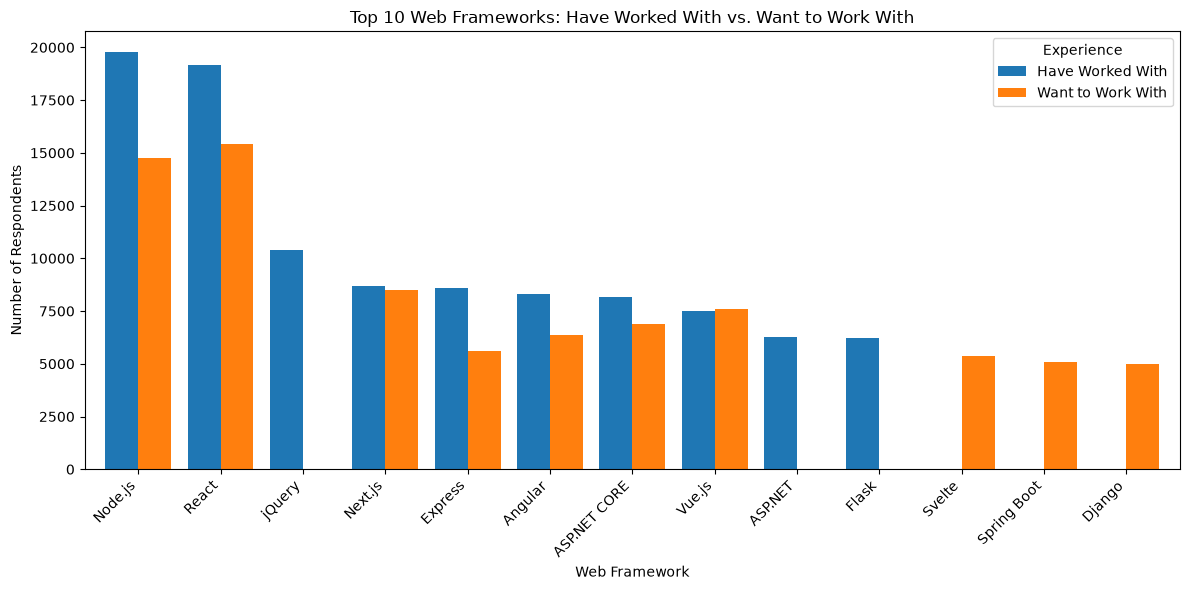

In [9]:
# Top 10 web frameworks respondents have worked with
have_counts = (
    df["WebframeHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Top 10 web frameworks respondents want to work with
want_counts = (
    df["WebframeWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Combine the results
comparison = pd.concat(
    [
        have_counts.rename("Have Worked With"),
        want_counts.rename("Want to Work With")
    ],
    axis=1
).fillna(0)

# Plot grouped bar chart
ax = comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Top 10 Web Frameworks: Have Worked With vs. Want to Work With")
plt.xlabel("Web Framework")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Experience")
plt.tight_layout()
plt.show()

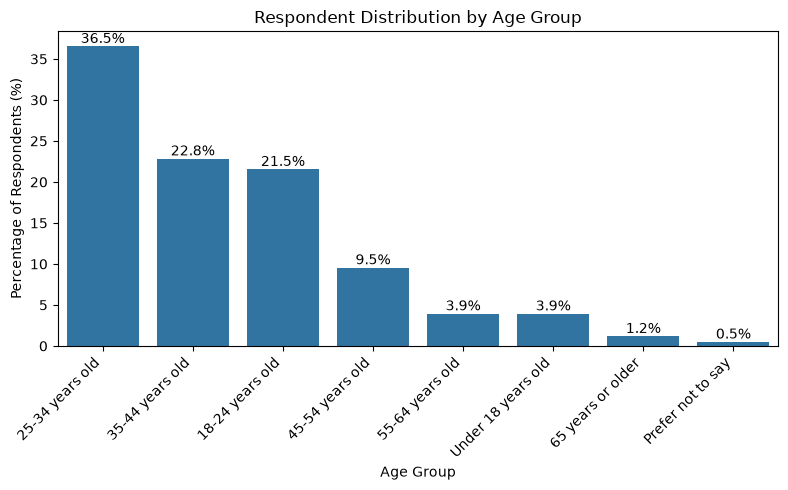

In [10]:

# Calculate percentage distribution by age group
age_percent = df["Age"].value_counts(normalize=True, dropna=False) * 100

# Create a DataFrame and sort by age group
age_distribution = age_percent.reset_index()
age_distribution.columns = ["Age", "Percentage"]

# Plot bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=age_distribution, x="Age", y="Percentage")

# Add percentage labels above bars
ax.bar_label(
    ax.containers[0],
    labels=[f"{v:.1f}%" for v in age_distribution["Percentage"]],
    padding=0
)

plt.title("Respondent Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Respondents (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
# CARTO map tiles and attribution
api_key = "cb1_472r_1_d630bd20f856aa9ce22b45e2"
tile_url = f"https://basemaps.cartocdn.com/rastertiles/voyager/{{z}}/{{x}}/{{y}}.png?key={api_key}"
attribution = '[OpenStreetMap](https://www.openstreetmap.org/copyright) contributors © [CARTO](https://carto.com/attributions)'

# Create the map
m = folium.Map(
    location=[20, 0],
    zoom_start=2,
    tiles=tile_url,
    attr=attribution
)

# Count respondents by country and age group
age_country = (
    df.dropna(subset=["Country", "Age"])
      .groupby(["Country", "Age"])
      .size()
      .reset_index(name="Respondents")
)

# Coordinates for selected countries
country_coords = {
    "United States of America": [39.8, -98.6],
    "Canada": [56.1, -106.3],
    "United Kingdom of Great Britain and Northern Ireland": [55.4, -3.4],
    "India": [20.6, 78.9],
    "Germany": [51.2, 10.4],
    "Brazil": [-14.2, -51.9],
    "France": [46.2, 2.2],
    "Australia": [-25.3, 133.8]
}

# Add markers with age-group information
for country, group in age_country.groupby("Country"):
    if country in country_coords:
        summary = "<br>".join(
            f"{row['Age']}: {row['Respondents']} respondents"
            for _, row in group.iterrows()
        )

        folium.Marker(
            location=country_coords[country],
            tooltip=country,
            popup=folium.Popup(
                f"<b>{country}</b><br>{summary}",
                max_width=300
            )
        ).add_to(m)

display(m)

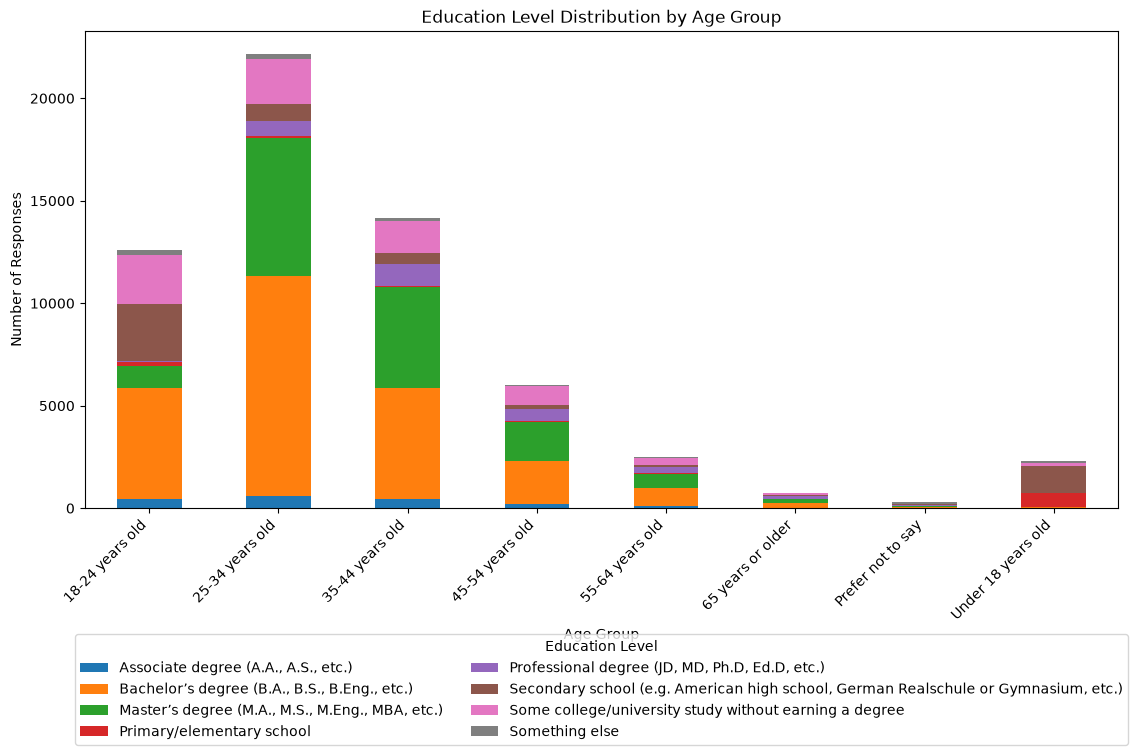

In [21]:
# Separate and explode EdLevel values
edlevel_exploded = (
    df.assign(EdLevel=df["EdLevel"].str.split(";"))
      .explode("EdLevel")
)

# Remove extra whitespace
edlevel_exploded["EdLevel"] = edlevel_exploded["EdLevel"].str.strip()

# Create stacked bar chart
age_education = pd.crosstab(
    edlevel_exploded["Age"],
    edlevel_exploded["EdLevel"]
)

age_education.plot(kind="bar", stacked=True, figsize=(12, 8))

plt.title("Education Level Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Responses")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Education Level",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=2
)
plt.tight_layout()
plt.show()

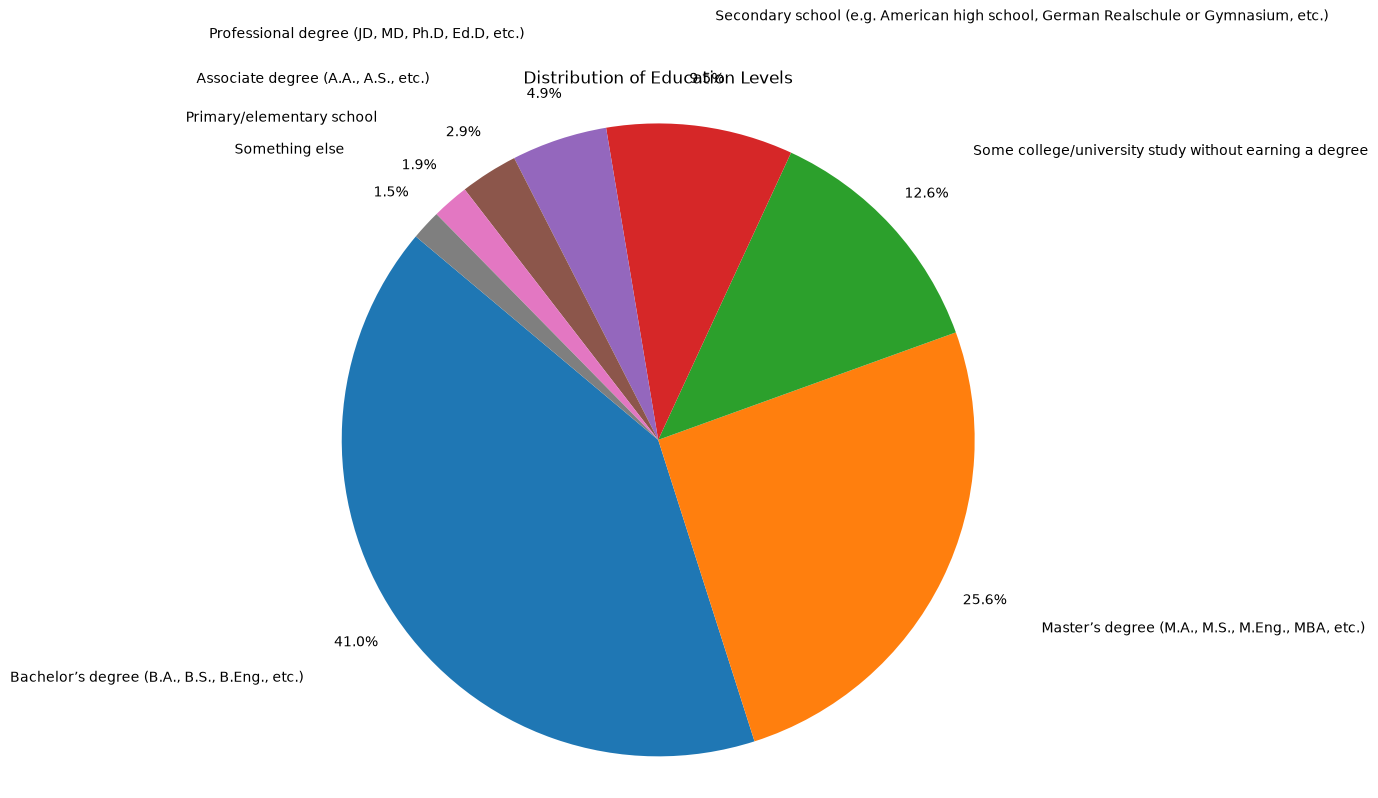

In [24]:
# Count respondents by education level
education_counts = df["EdLevel"].dropna().value_counts()

# Create pie chart
plt.figure(figsize=(12, 8))
plt.pie(
    education_counts,
    labels=education_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=1.15,
    labeldistance=1.35
)

plt.title("Distribution of Education Levels")
plt.axis("equal")
plt.tight_layout()
plt.show()